# Reading & Saving Medical Images in Python
### Class example · SimpleITK and nibabel

What this notebook covers:

1. **Setup**: imports and data paths
2. **Read with SimpleITK**: a single file or a DICOM series
3. **Image attributes**: size, spacing, origin, direction, metadata
4. **To NumPy**: array order, intensity statistics, histogram
5. **View slices**: axial, coronal and sagittal views, windowing, montage, MIP, slider
6. **Process and save with SimpleITK**: mask, overlay, volume, resampling, file formats
7. **Read and save with nibabel**: header, affine, `get_fdata` vs `dataobj`, canonical orientation
8. **SimpleITK ↔ nibabel**: axis order, LPS vs RAS, in-memory conversion
9. **Batch processing**: many scans in one loop
10. **Exercises**

> **No data yet?** Leave the paths in section 1 empty. The notebook then builds a synthetic CT-like phantom, so every cell still runs.

In [48]:
# Run once if the packages are missing (then restart the kernel)
# %pip install SimpleITK nibabel numpy matplotlib pandas tqdm ipywidgets

## 1 · Setup

In [49]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import SimpleITK as sitk
import nibabel as nib
from nibabel.affines import apply_affine
import os

print("SimpleITK", sitk.Version.VersionString())
print("nibabel  ", nib.__version__)
plt.rcParams["figure.dpi"] = 100

SimpleITK 2.3.1-g42ce2
nibabel   5.2.1


**Fill in your data here.** Use either:
* `IMAGE_PATH`: one file such as `.nii.gz`, `.nii`, `.mha`, `.mhd`, `.nrrd` or a single `.dcm`, **or**
* `DICOM_DIR`: a folder containing one DICOM series (one file per slice).

If both are filled, `DICOM_DIR` is used. If both are empty, the notebook uses a synthetic phantom.

In [50]:
# ------------------ fill these in ------------------
IMAGE_PATH = "../../images3d/3493_img.nii.gz"      # e.g. "data/ct_head.nii.gz"
BATCH_DIR  = ""      # e.g. "data/scans/"  (folder of many .nii.gz, used in section 9)
# ---------------------------------------------------
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print(os.path.exists(IMAGE_PATH))

True


## 2 · Reading an image with SimpleITK

* `sitk.ReadImage(path)` picks the right reader from the file extension.
* `sitk.ImageSeriesReader` collects a DICOM series. Slices are sorted by their **position in the body**, not by file name.
* The phantom is only a stand-in so the notebook runs without data: an ellipsoid "head" (40 HU), a bony shell (800 HU) and a small lesion (120 HU).

In [51]:
def make_phantom_array(size=(160, 192, 96), spacing=(1.0, 1.0, 2.5), seed=0):
    # Synthetic CT-like volume in Hounsfield units, returned as a (z, y, x) array.
    nx, ny, nz = size
    z, y, x = np.mgrid[0:nz, 0:ny, 0:nx].astype(np.float32)
    xm, ym, zm = (x - nx / 2) * spacing[0], (y - ny / 2) * spacing[1], (z - nz / 2) * spacing[2]
    ell = lambda a, b, c, dx=0, dy=0, dz=0: ((xm - dx) / a) ** 2 + ((ym - dy) / b) ** 2 + ((zm - dz) / c) ** 2 <= 1
    arr = np.full((nz, ny, nx), -1000, np.float32)       # air
    arr[ell(70, 85, 110)] = 40                           # soft tissue
    arr[ell(66, 81, 106) & ~ell(60, 75, 100)] = 800      # bony shell ("skull")
    arr[ell(12, 12, 12, dx=20, dy=-15, dz=10)] = 120     # lesion
    arr += np.random.default_rng(seed).normal(0, 15, arr.shape)
    return arr.astype(np.int16)

def make_phantom(size=(160, 192, 96), spacing=(1.0, 1.0, 2.5), seed=0):
    img = sitk.GetImageFromArray(make_phantom_array(size, spacing, seed))
    img.SetSpacing(spacing)
    img.SetOrigin([-n / 2 * s for n, s in zip(size, spacing)])
    return img

In [52]:
def read_image(image_path=""):
    if image_path:
        return sitk.ReadImage((image_path))
    print("No path given -> using the synthetic phantom")
   
img = read_image(IMAGE_PATH)

def read_dicom(dicom_dir):
    # Read one DICOM series from a folder. Returns (image, reader); the reader keeps the per-slice tags.
    reader = sitk.ImageSeriesReader()
    series_ids = reader.GetGDCMSeriesIDs(str(dicom_dir))
    if not series_ids:
        raise FileNotFoundError(f"No DICOM series found in {dicom_dir}")
    if len(series_ids) > 1:
        print(f"{len(series_ids)} series found -> reading the first one")
    files = reader.GetGDCMSeriesFileNames(str(dicom_dir), series_ids[0])   # sorted by slice position
    reader.SetFileNames(files)
    reader.MetaDataDictionaryArrayUpdateOn()   # keep the tags so show_metadata can read them
    reader.LoadPrivateTagsOn()
    print(f"Reading {len(files)} DICOM slice(s) from {dicom_dir}")
    return reader.Execute(), reader


# img, dicom_reader = read_dicom(DICOM_DIR)

# This notebook works with 3D scalar images
if img.GetDimension() == 4:
    print("4D image (e.g. fMRI): keeping the first volume")
    img = img[:, :, :, 0]
assert img.GetDimension() == 3, "Please use a 3D image for this notebook"
print(type(img))

<class 'SimpleITK.SimpleITK.Image'>


## 3 · Image attributes

An image is **voxels + geometry + metadata**. SimpleITK stores the geometry as separate properties:

| Method | Meaning |
|---|---|
| `GetSize()` | number of voxels along **(x, y, z)** |
| `GetSpacing()` | voxel size in mm |
| `GetOrigin()` | physical position (mm) of voxel (0,0,0), **LPS** convention |
| `GetDirection()` | 3×3 direction cosines (flattened) |
| `GetPixelIDTypeAsString()` | voxel data type |

In [53]:
def describe(image):
    size, spacing = image.GetSize(), image.GetSpacing()
    d = image.GetDimension()
    try:
        orient = sitk.DICOMOrientImageFilter.GetOrientationFromDirectionCosines(image.GetDirection())
    except Exception:
        orient = "n/a"
    print(f"Dimension       : {d}")
    print(f"Size (x, y, z)  : {size} voxels")
    print(f"Spacing (mm)    : {tuple(round(s, 4) for s in spacing)}")
    print(f"Origin (mm, LPS): {tuple(round(o, 2) for o in image.GetOrigin())}")
    print(f"Direction       : {np.round(np.array(image.GetDirection()).reshape(d, d), 3).tolist()}")
    print(f"Orientation code: {orient}   (array axes point towards these patient directions)")
    print(f"Pixel type      : {image.GetPixelIDTypeAsString()}")
    print(f"Components/voxel: {image.GetNumberOfComponentsPerPixel()}")
    print(f"Physical extent : {tuple(round(n * s, 1) for n, s in zip(size, spacing))} mm")
    print(f"Voxel volume    : {np.prod(spacing):.4f} mm^3")
    print(f"Total voxels    : {np.prod(size):,}")

describe(img)

Dimension       : 3
Size (x, y, z)  : (160, 224, 192) voxels
Spacing (mm)    : (1.0, 1.0, 1.0)
Origin (mm, LPS): (0.0, 0.0, 0.0)
Direction       : [[-1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]]
Orientation code: RAS   (array axes point towards these patient directions)
Pixel type      : 32-bit float
Components/voxel: 1
Physical extent : (160.0, 224.0, 192.0) mm
Voxel volume    : 1.0000 mm^3
Total voxels    : 6,881,280


### Metadata
NIfTI files expose their header fields here. DICOM gives you the tags (`group|element`).
⚠️ DICOM headers can contain **patient-identifying information**, so print only what you need.

### Voxel index ↔ physical point
`physical = origin + direction @ (index * spacing)`

In [54]:
centre_idx = [s // 2 for s in img.GetSize()]
p = img.TransformIndexToPhysicalPoint(centre_idx)
print("centre voxel (i, j, k):", centre_idx)
print("-> physical (mm, LPS) :", np.round(p, 2))
print("-> back to index      :", img.TransformPhysicalPointToIndex(p))

D = np.array(img.GetDirection()).reshape(3, 3)
manual = np.array(img.GetOrigin()) + D @ (np.array(centre_idx) * np.array(img.GetSpacing()))
print("manual formula        :", np.round(manual, 2))

centre voxel (i, j, k): [80, 112, 96]
-> physical (mm, LPS) : [ -80. -112.   96.]
-> back to index      : (80, 112, 96)
manual formula        : [ -80. -112.   96.]


## 4 · From image to NumPy

⚠️ `sitk.GetArrayFromImage` returns the axes **reversed**: `(z, y, x)`. `arr[k]` is axial slice *k*.
The array keeps **no geometry**: spacing, origin and direction stay in `img`.

In [55]:
arr = sitk.GetArrayFromImage(img)          # a copy; GetArrayViewFromImage gives a read-only view
print("img.GetSize():", img.GetSize(), " (x, y, z)")
print("arr.shape    :", arr.shape, " (z, y, x)  <- reversed!")
print("dtype        :", arr.dtype)
print(f"min / max    : {arr.min()} / {arr.max()}")
print(f"mean ± std   : {arr.mean():.1f} ± {arr.std():.1f}")
print("percentiles 1 / 50 / 99:", np.percentile(arr, [1, 50, 99]).round(1))

IS_CT = arr.min() < -500      # crude guess: CT has air at about -1000 HU
print("Looks like CT (Hounsfield units)?", IS_CT)

img.GetSize(): (160, 224, 192)  (x, y, z)
arr.shape    : (192, 224, 160)  (z, y, x)  <- reversed!
dtype        : float32
min / max    : 0.0 / 216.26962280273438
mean ± std   : 20.1 ± 35.2
percentiles 1 / 50 / 99: [  0.    0.  113.4]
Looks like CT (Hounsfield units)? False


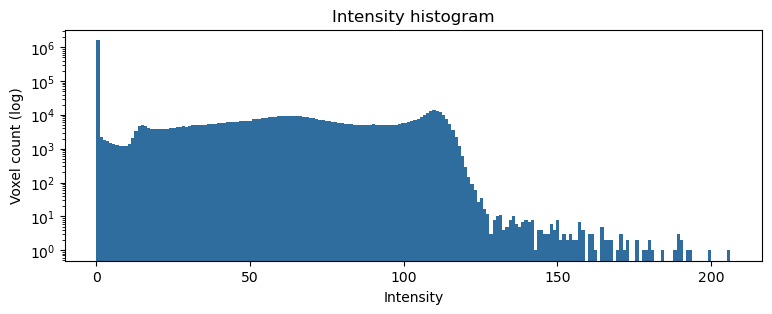

In [56]:
sample = arr.ravel()[:: max(1, arr.size // 2_000_000)]   # subsample big volumes
plt.figure(figsize=(9, 3))
plt.hist(sample, bins=200, log=True, color="#2f6d9e")
plt.xlabel("Intensity (HU)" if IS_CT else "Intensity")
plt.ylabel("Voxel count (log)")
plt.title("Intensity histogram")
plt.show()

## 5 · Viewing axial, coronal and sagittal slices

Three things to get right when showing slices:
1. **Orientation.** We first reorient to **LPS** (`sitk.DICOMOrient`) so every scan looks the same. Array axes then point x→Left, y→Posterior, z→Superior.
2. **Aspect ratio.** Voxels are often not cubic (e.g. 0.5 × 0.5 × 2.5 mm). Pass `aspect = row spacing / column spacing` to `imshow`, or coronal and sagittal views look squashed.
3. **Windowing.** CT spans about −1000 to 3000 HU. Choose a *window* (level, width) for the tissue you want to see.

Images below follow the **radiological convention**: the patient's right appears on the left of the screen.

In [57]:
img_lps = sitk.DICOMOrient(img, "LPS")
vol = sitk.GetArrayFromImage(img_lps)             # (z, y, x)
spacing = img_lps.GetSpacing()                    # (sx, sy, sz)
print("reoriented shape (z, y, x):", vol.shape, " spacing (x, y, z):", spacing)

# CT windows as (level, width) in HU
WINDOWS = {"brain": (40, 80), "subdural": (75, 215), "soft tissue": (40, 400),
           "lung": (-600, 1500), "bone": (400, 1800)}

def window_limits(a, window=None):
    # (vmin, vmax) for imshow. window: None = robust auto, a WINDOWS name, or (level, width)
    if window is None:
        lo, hi = np.percentile(a, [1, 99])
        return float(lo), float(hi)
    level, width = WINDOWS[window] if isinstance(window, str) else window
    return level - width / 2, level + width / 2

reoriented shape (z, y, x): (192, 224, 160)  spacing (x, y, z): (1.0, 1.0, 1.0)


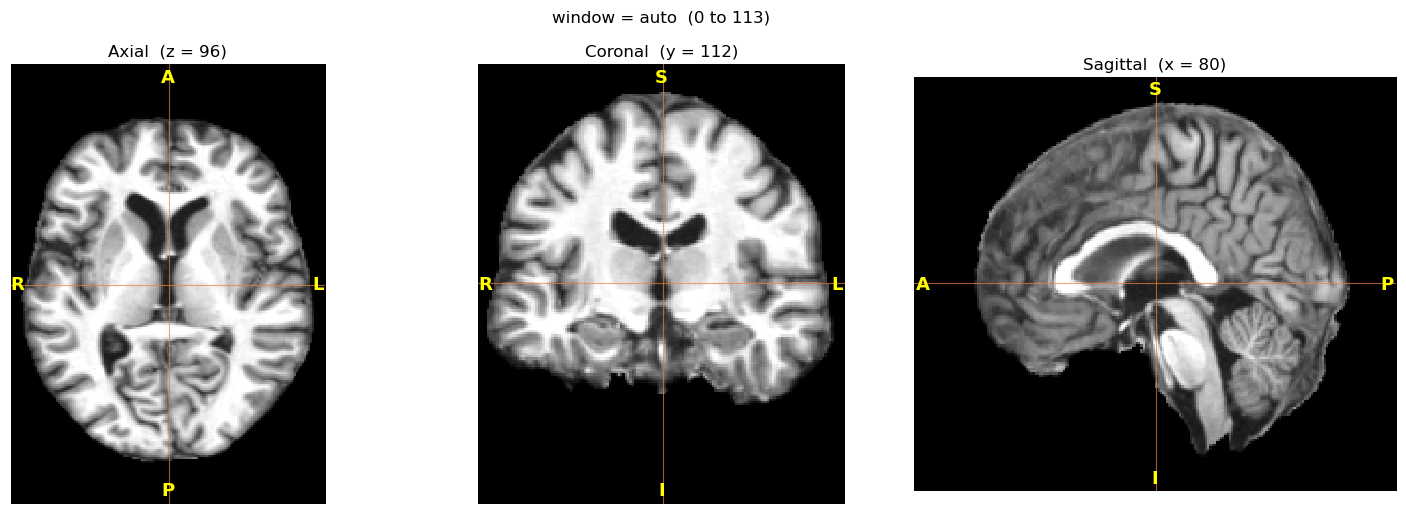

In [58]:
def ortho_slices(v, k, j, i):
    # Axial, coronal and sagittal 2D slices of a (z, y, x) LPS volume
    return [v[k, :, :], v[:, j, :], v[:, :, i]]

def show_orthogonal(vol, spacing, index=None, window=None, overlay=None,
                    crosshair=True, title=""):
    # vol: (z, y, x) array in LPS orientation; spacing: (sx, sy, sz); index: (k, j, i)
    sx, sy, sz = spacing
    nz, ny, nx = vol.shape
    k, j, i = index if index is not None else (nz // 2, ny // 2, nx // 2)
    vmin, vmax = window_limits(vol, window)
    names   = [f"Axial  (z = {k})", f"Coronal  (y = {j})", f"Sagittal  (x = {i})"]
    aspects = [sy / sx, sz / sx, sz / sy]
    origins = ["upper", "lower", "lower"]               # 'lower' puts the head at the top
    labels  = [("R", "L", "A", "P"), ("R", "L", "S", "I"), ("A", "P", "S", "I")]  # left, right, top, bottom
    cross   = [(i, j), (i, k), (j, k)]                  # (vertical line, horizontal line)
    masks   = ortho_slices(overlay, k, j, i) if overlay is not None else [None] * 3

    fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
    for ax, sl, m, name, asp, org, lab, (cv, ch) in zip(
            axes, ortho_slices(vol, k, j, i), masks, names, aspects, origins, labels, cross):
        ax.imshow(sl, cmap="gray", vmin=vmin, vmax=vmax, aspect=asp, origin=org,
                  interpolation="nearest")
        if m is not None:
            ax.imshow(np.ma.masked_where(m == 0, m), cmap="autumn", alpha=0.5,
                      aspect=asp, origin=org, interpolation="nearest")
        if crosshair:
            ax.axvline(cv, color="#e8833a", lw=0.8, alpha=0.7)
            ax.axhline(ch, color="#e8833a", lw=0.8, alpha=0.7)
        for txt, xy in zip(lab, [(0.02, 0.5), (0.98, 0.5), (0.5, 0.97), (0.5, 0.03)]):
            ax.text(*xy, txt, transform=ax.transAxes, color="yellow", fontsize=13,
                    ha="center", va="center", fontweight="bold")
        ax.set_title(name)
        ax.axis("off")
    fig.suptitle(title or f"window = {window or 'auto'}  ({vmin:.0f} to {vmax:.0f})")
    plt.tight_layout()
    plt.show()

show_orthogonal(vol, spacing)

**Try:** change the window. For a head CT, compare `"brain"`, `"bone"` and `"soft tissue"`.

In [59]:
if IS_CT:
    for w in ["brain", "bone"]:
        show_orthogonal(vol, spacing, window=w)

### Why the aspect ratio matters
The left image ignores the spacing; the right one uses `aspect = sz / sx`.

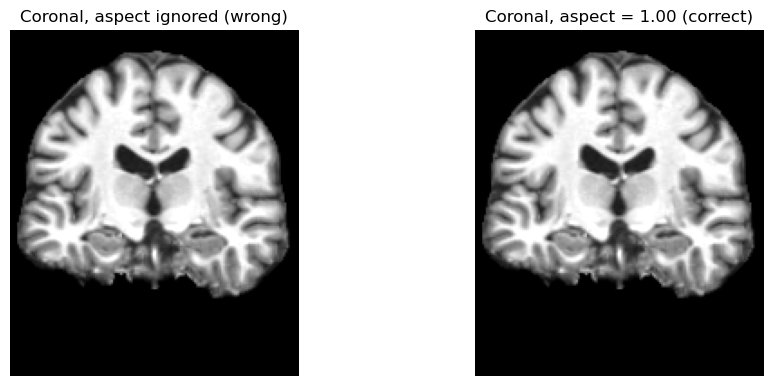

In [60]:
j = vol.shape[1] // 2
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
vmin, vmax = window_limits(vol)
axes[0].imshow(vol[:, j, :], cmap="gray", vmin=vmin, vmax=vmax, origin="lower")
axes[0].set_title("Coronal, aspect ignored (wrong)")
axes[1].imshow(vol[:, j, :], cmap="gray", vmin=vmin, vmax=vmax, origin="lower",
               aspect=spacing[2] / spacing[0])
axes[1].set_title(f"Coronal, aspect = {spacing[2] / spacing[0]:.2f} (correct)")
for ax in axes: ax.axis("off")
plt.show()

### Montage: many slices at once

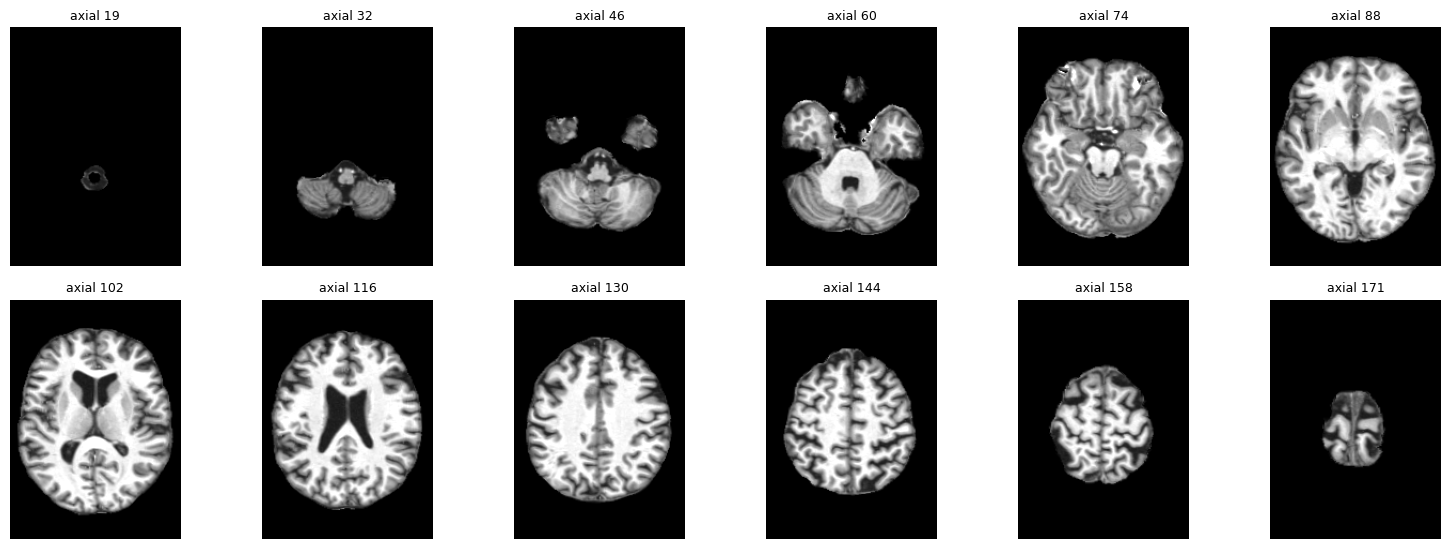

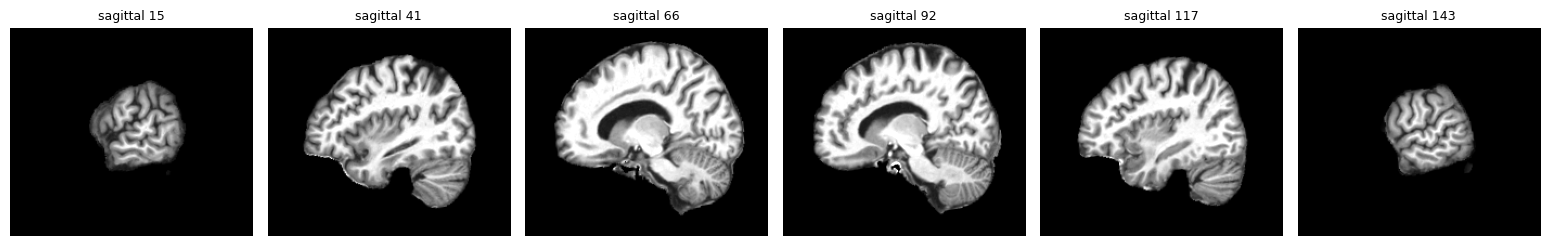

In [61]:
def show_montage(vol, spacing, plane="axial", n=12, cols=6, window=None):
    sx, sy, sz = spacing
    axis = {"axial": 0, "coronal": 1, "sagittal": 2}[plane]
    aspect = {"axial": sy / sx, "coronal": sz / sx, "sagittal": sz / sy}[plane]
    origin = "upper" if plane == "axial" else "lower"
    idx = np.linspace(0.1, 0.9, n) * (vol.shape[axis] - 1)
    vmin, vmax = window_limits(vol, window)
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2.6 * cols, 2.8 * rows))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, s in zip(np.ravel(axes), idx.astype(int)):
        ax.imshow(np.take(vol, s, axis=axis), cmap="gray", vmin=vmin, vmax=vmax,
                  aspect=aspect, origin=origin)
        ax.set_title(f"{plane} {s}", fontsize=9)
    plt.tight_layout()
    plt.show()

show_montage(vol, spacing, "axial")
show_montage(vol, spacing, "sagittal", n=6)

### Maximum-intensity projection (MIP)
Taking the maximum along one axis makes bright structures (bone, contrast-filled vessels) easy to see.

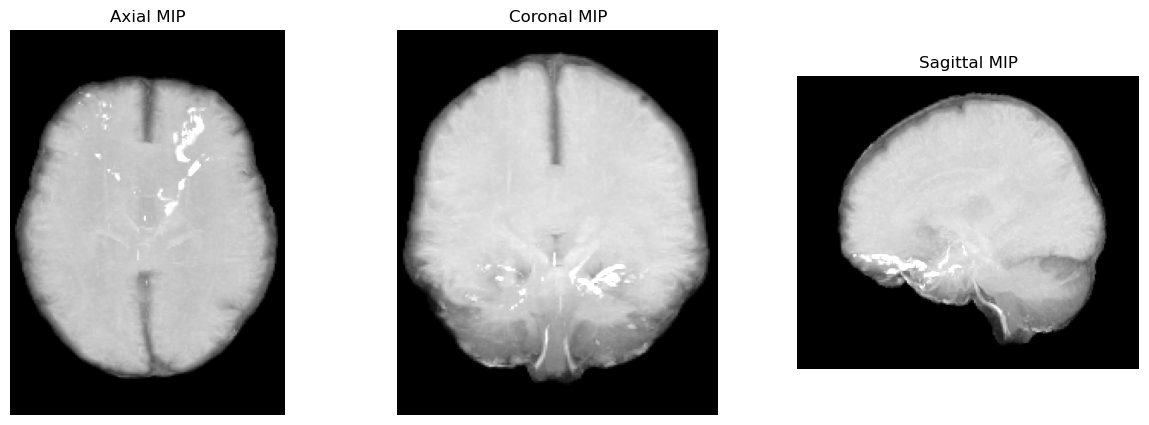

In [62]:
sx, sy, sz = spacing
mips = [("Axial MIP", vol.max(axis=0), sy / sx, "upper"),
        ("Coronal MIP", vol.max(axis=1), sz / sx, "lower"),
        ("Sagittal MIP", vol.max(axis=2), sz / sy, "lower")]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, im, asp, org) in zip(axes, mips):
    ax.imshow(im, cmap="gray", aspect=asp, origin=org, vmin=np.percentile(im, 1), vmax=np.percentile(im, 99.5))
    ax.set_title(name); ax.axis("off")
plt.show()

### Interactive slider (needs `ipywidgets`)

In [63]:
try:
    from ipywidgets import interact, IntSlider, Dropdown
    nz, ny, nx = vol.shape
    @interact(k=IntSlider(nz // 2, 0, nz - 1, description="axial z"),
              j=IntSlider(ny // 2, 0, ny - 1, description="coronal y"),
              i=IntSlider(nx // 2, 0, nx - 1, description="sagittal x"),
              window=Dropdown(options=[("auto", None)] + [(w, w) for w in WINDOWS], description="window"))
    def _browse(k, j, i, window):
        show_orthogonal(vol, spacing, index=(k, j, i), window=window)
except ImportError:
    print("Install ipywidgets for sliders:  %pip install ipywidgets")

Install ipywidgets for sliders:  %pip install ipywidgets


## 6 · Process and save with SimpleITK

Workflow: **image → array → process → array → image (+ copy geometry) → file.**

In [64]:
# Threshold: bone in CT (> 300 HU); for MRI use a high percentile instead
threshold = 300 if IS_CT else float(np.percentile(arr, 95))
mask_arr = (arr > threshold).astype(np.uint8)
print(f"threshold = {threshold:.1f}, mask voxels = {mask_arr.sum():,}")

mask = sitk.GetImageFromArray(mask_arr)
mask.CopyInformation(img)          # <- spacing, origin and direction from the original
sitk.WriteImage(mask, str(OUTPUT_DIR / "mask_sitk.nii.gz"))

volume_ml = mask_arr.sum() * np.prod(img.GetSpacing()) / 1000      # 1 ml = 1000 mm^3
print(f"Mask volume: {volume_ml:.1f} ml")

threshold = 105.1, mask voxels = 344,064
Mask volume: 344.1 ml


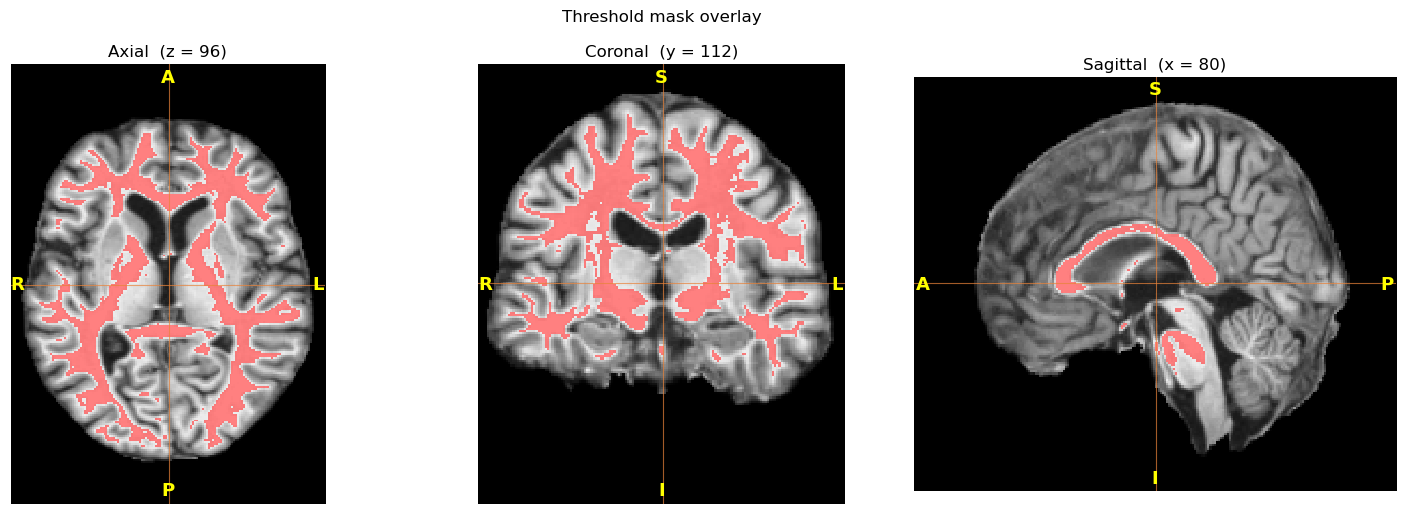

In [65]:
# Overlay the mask (reoriented the same way as the image)
mask_vol = sitk.GetArrayFromImage(sitk.DICOMOrient(mask, "LPS"))
show_orthogonal(vol, spacing, overlay=mask_vol, window="bone" if IS_CT else None,
                title="Threshold mask overlay")

### The same thing without NumPy
SimpleITK filters keep the geometry automatically.

In [66]:
mask2 = sitk.BinaryThreshold(img, lowerThreshold=threshold + 1e-3, upperThreshold=float(arr.max()) + 1,
                             insideValue=1, outsideValue=0)
print("same result as the NumPy version:", np.array_equal(sitk.GetArrayFromImage(mask2), mask_arr))

# Connected components: how many separate objects, and how big?
cc = sitk.ConnectedComponent(mask2)
stats = sitk.LabelShapeStatisticsImageFilter()
stats.Execute(cc)
labels = sorted(stats.GetLabels(), key=stats.GetPhysicalSize, reverse=True)
print(f"{len(labels)} components; largest 3 (ml):",
      [round(stats.GetPhysicalSize(l) / 1000, 1) for l in labels[:3]])

same result as the NumPy version: False
775 components; largest 3 (ml): [339.8, 0.9, 0.5]


### ⚠️ Pitfall: forgetting `CopyInformation`

In [67]:
bad = sitk.GetImageFromArray(mask_arr)       # no geometry copied
print("original spacing / origin:", img.GetSpacing(), np.round(img.GetOrigin(), 1))
print("bad mask spacing / origin:", bad.GetSpacing(), bad.GetOrigin())
print("-> in a viewer this mask would be the wrong size and in the wrong place")

original spacing / origin: (1.0, 1.0, 1.0) [0. 0. 0.]
bad mask spacing / origin: (1.0, 1.0, 1.0) (0.0, 0.0, 0.0)
-> in a viewer this mask would be the wrong size and in the wrong place


### Resampling to isotropic 1 mm voxels
Common before deep learning or 3D measurements. Use **linear** interpolation for images and **nearest neighbour** for masks (labels must stay integers).

In [68]:
def resample(image, new_spacing=(1.0, 1.0, 1.0), is_label=False):
    old_size, old_spacing = image.GetSize(), image.GetSpacing()
    new_size = [int(round(n * s / ns)) for n, s, ns in zip(old_size, old_spacing, new_spacing)]
    interp = sitk.sitkNearestNeighbor if is_label else sitk.sitkLinear
    fill = 0.0 if is_label else float(sitk.GetArrayViewFromImage(image).min())
    return sitk.Resample(image, new_size, sitk.Transform(), interp, image.GetOrigin(),
                         new_spacing, image.GetDirection(), fill, image.GetPixelID())

img_iso = resample(img)
mask_iso = resample(mask, is_label=True)
print("before:", img.GetSize(), np.round(img.GetSpacing(), 3))
print("after :", img_iso.GetSize(), img_iso.GetSpacing())
print("mask labels after resampling:", np.unique(sitk.GetArrayViewFromImage(mask_iso)))

before: (160, 224, 192) [1. 1. 1.]
after : (160, 224, 192) (1.0, 1.0, 1.0)
mask labels after resampling: [0 1]


### Writing: the extension picks the format

In [69]:
for name in ["image_sitk.nii.gz", "image_sitk.nii", "image_sitk.mha", "image_sitk.nrrd"]:
    sitk.WriteImage(img, str(OUTPUT_DIR / name), useCompression=name.endswith((".gz", ".mha", ".nrrd")))
    print(f"{name:<20} {(OUTPUT_DIR / name).stat().st_size / 1e6:7.2f} MB")

# Round trip: is the geometry preserved?
back = sitk.ReadImage(str(OUTPUT_DIR / "image_sitk.nii.gz"))
print("\nspacing equal  :", np.allclose(back.GetSpacing(), img.GetSpacing()))
print("origin equal   :", np.allclose(back.GetOrigin(), img.GetOrigin(), atol=1e-3))
print("direction equal:", np.allclose(back.GetDirection(), img.GetDirection(), atol=1e-5))
print("voxels equal   :", np.array_equal(sitk.GetArrayViewFromImage(back), arr))

image_sitk.nii.gz       7.26 MB
image_sitk.nii         27.53 MB
image_sitk.mha          7.27 MB
image_sitk.nrrd         7.27 MB

spacing equal  : True
origin equal   : True
direction equal: True
voxels equal   : True


MetaImageIO (0x12da6fc00): Unsupported or empty metaData item ITK_FileNotes of type NSt3__112basic_stringIcNS_11char_traitsIcEENS_9allocatorIcEEEEfound, won't be written to image file

MetaImageIO (0x12da6fc00): Unsupported or empty metaData item aux_file of type NSt3__112basic_stringIcNS_11char_traitsIcEENS_9allocatorIcEEEEfound, won't be written to image file

MetaImageIO (0x12da6fc00): Unsupported or empty metaData item descrip of type NSt3__112basic_stringIcNS_11char_traitsIcEENS_9allocatorIcEEEEfound, won't be written to image file

MetaImageIO (0x12da6fc00): Unsupported or empty metaData item intent_name of type NSt3__112basic_stringIcNS_11char_traitsIcEENS_9allocatorIcEEEEfound, won't be written to image file

MetaImageIO (0x12da6fc00): Unsupported or empty metaData item qto_xyz of type N3itk6MatrixIfLj4ELj4EEEfound, won't be written to image file



> If you read a **DICOM series**, the cell above has just converted it to NIfTI: that is the one-line DICOM → NIfTI conversion. Patient tags are **not** copied into the NIfTI header.

## 7 · Reading and saving with nibabel

nibabel works best with NIfTI. If your input is NIfTI we load it directly; otherwise we load the NIfTI that SimpleITK just wrote.

In [82]:
nifti_path = '../../images3d/3493_img.nii.gz' 
nimg = nib.load(nifti_path)            # lazy: only the header is read here
print("file         :", nifti_path)
print("class        :", type(nimg).__name__)
print("shape        :", nimg.shape, " (x, y, z)  <- NOT reversed")
print("zooms (mm)   :", nimg.header.get_zooms())
print("dtype on disk:", nimg.get_data_dtype())
print("units        :", nimg.header.get_xyzt_units())
print("axcodes      :", nib.aff2axcodes(nimg.affine), " (RAS+ world)")
print("affine:\n", np.round(nimg.affine, 3))

file         : ../images3d/3493_img.nii.gz
class        : Nifti1Image
shape        : (160, 224, 192)  (x, y, z)  <- NOT reversed
zooms (mm)   : (1.0, 1.0, 1.0)
dtype on disk: float32
units        : ('unknown', 'unknown')
axcodes      : ('R', 'A', 'S')  (RAS+ world)
affine:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]


In [71]:
hdr = nimg.header
print("dim       :", hdr["dim"])
print("pixdim    :", np.round(hdr["pixdim"], 4))
print("qform/sform code:", int(hdr["qform_code"]), "/", int(hdr["sform_code"]))
print("scl_slope / scl_inter:", hdr["scl_slope"], "/", hdr["scl_inter"])
print("description:", hdr["descrip"])
# print(hdr)   # uncomment to see every header field

dim       : [  3 160 224 192   1   1   1   1]
pixdim    : [1. 1. 1. 1. 1. 1. 1. 1.]
qform/sform code: 0 / 2
scl_slope / scl_inter: nan / nan
description: b''


### `get_fdata()` vs `dataobj`
* `get_fdata()` always returns **float64**, with scaling applied. Simple, but it uses 8 bytes per voxel.
* `np.asanyarray(nimg.dataobj)` keeps the stored type, e.g. int16 or uint8 for labels.

In [83]:
data = nimg.get_fdata()
raw = np.asanyarray(nimg.dataobj)
print(f"get_fdata : {data.dtype}, {data.nbytes / 1e6:.1f} MB")
print(f"dataobj   : {raw.dtype}, {raw.nbytes / 1e6:.1f} MB")

# The affine maps voxel (i, j, k) -> world (x, y, z) in mm, RAS+
ijk = np.array(nimg.shape[:3]) // 2
print("centre voxel", ijk, "->", np.round(apply_affine(nimg.affine, ijk), 2), "mm (RAS)")

get_fdata : float64, 55.1 MB
dataobj   : float32, 27.5 MB
centre voxel [ 80 112  96] -> [ 80. 112.  96.] mm (RAS)


### Viewing slices with nibabel
`nib.as_closest_canonical` flips and permutes the axes to **RAS+**. Then:
`data[:, :, k]` is axial, `data[:, j, :]` coronal, `data[i, :, :]` sagittal.
We transpose (`.T`) so rows are the vertical axis. We flip left-right to use the same radiological convention as section 5.

canonical axcodes: ('R', 'A', 'S')  shape: (160, 224, 192)


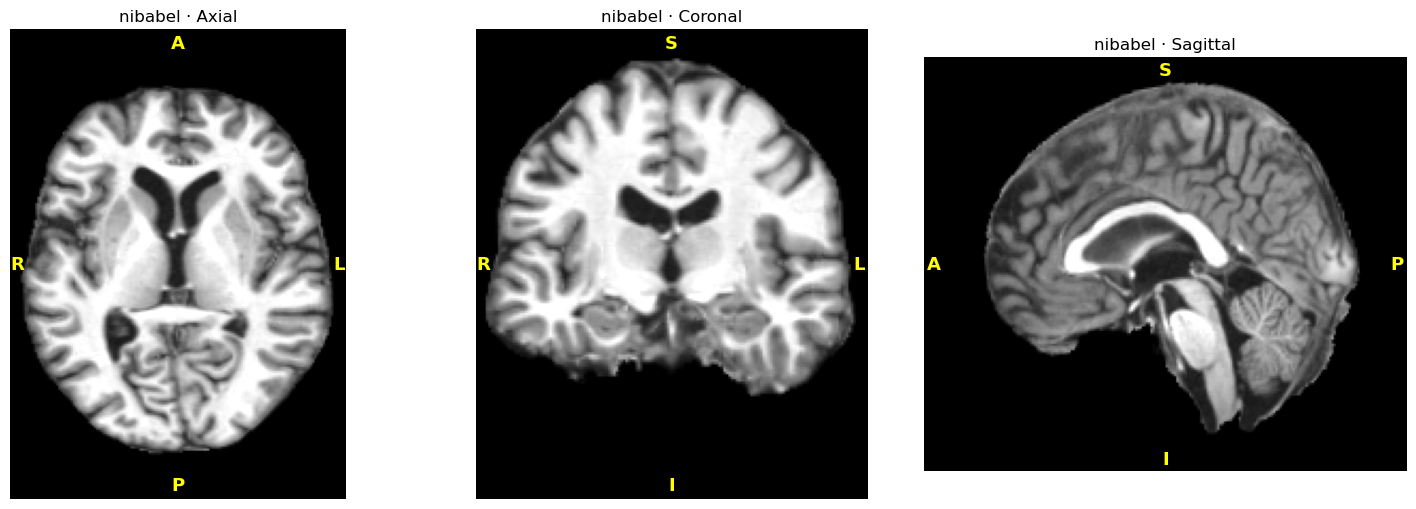

In [84]:
can = nib.as_closest_canonical(nimg)
cdata = can.get_fdata()
zx, zy, zz = can.header.get_zooms()[:3]
nx, ny, nz = cdata.shape[:3]
i, j, k = nx // 2, ny // 2, nz // 2
print("canonical axcodes:", nib.aff2axcodes(can.affine), " shape:", cdata.shape)

views = [("Axial",    cdata[:, :, k].T[:, ::-1], zy / zx, ("R", "L", "A", "P")),
         ("Coronal",  cdata[:, j, :].T[:, ::-1], zz / zx, ("R", "L", "S", "I")),
         ("Sagittal", cdata[i, :, :].T[:, ::-1], zz / zy, ("A", "P", "S", "I"))]
vmin, vmax = window_limits(cdata)
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
for ax, (name, sl, asp, lab) in zip(axes, views):
    ax.imshow(sl, cmap="gray", origin="lower", aspect=asp, vmin=vmin, vmax=vmax)
    for txt, xy in zip(lab, [(0.02, 0.5), (0.98, 0.5), (0.5, 0.97), (0.5, 0.03)]):
        ax.text(*xy, txt, transform=ax.transAxes, color="yellow", fontsize=13,
                ha="center", va="center", fontweight="bold")
    ax.set_title(f"nibabel · {name}"); ax.axis("off")
plt.tight_layout(); plt.show()

These should look exactly like the SimpleITK views in section 5: same data and same convention, with different code to get there.

### Saving with nibabel
`Nifti1Image(array, affine, header)` → `nib.save`. Reuse the **affine** so the result lines up with the scan, and set the **dtype**.

In [85]:
nib_thr = 300 if IS_CT else float(np.percentile(data, 95))
nib_mask = (data > nib_thr).astype(np.uint8)

out = nib.Nifti1Image(nib_mask, nimg.affine, nimg.header)
out.set_data_dtype(np.uint8)          # the copied header still says the old type
nib.save(out, OUTPUT_DIR / "mask_nib.nii.gz")

# float example: a normalised image saved as float32 (half the size of float64)
norm = ((data - data.mean()) / data.std()).astype(np.float32)
affine = nimg.affine 
print(affine)
affine[1,1]=2
print(affine)
out_f = nib.Nifti1Image(norm, affine)
out_f.set_data_dtype(np.float32)
nib.save(out_f, OUTPUT_DIR / "image_zscore_nib.nii.gz")

check = nib.load(OUTPUT_DIR / "mask_nib.nii.gz")
print("saved dtype :", check.get_data_dtype())
print("affine equal:", np.allclose(check.affine, nimg.affine))
print("same mask as SimpleITK:",
      np.array_equal(np.asanyarray(check.dataobj), mask_arr.transpose(2, 1, 0)))

[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
[[1. 0. 0. 0.]
 [0. 2. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
saved dtype : uint8
affine equal: False
same mask as SimpleITK: True


### Building an image from scratch
With no reference image you must write the affine yourself. Here: 2 mm isotropic voxels, origin at (−90, −126, −72) mm.

In [75]:
affine = np.array([[2, 0, 0,  -90],
                   [0, 2, 0, -126],
                   [0, 0, 2,  -72],
                   [0, 0, 0,    1]], dtype=float)
toy = nib.Nifti1Image(np.zeros((91, 109, 91), np.uint8), affine)
print("zooms:", toy.header.get_zooms(), " axcodes:", nib.aff2axcodes(affine))
print("voxel (10, 20, 30) ->", apply_affine(affine, [10, 20, 30]), "mm")

zooms: (2.0, 2.0, 2.0)  axcodes: ('R', 'A', 'S')
voxel (10, 20, 30) -> [-70. -86. -12.] mm


## 8 · SimpleITK ↔ nibabel

| | SimpleITK | nibabel |
|---|---|---|
| array order | (z, y, x) | (x, y, z) |
| world coordinates | LPS | RAS+ |
| geometry | spacing + origin + direction | 4×4 affine |

`LPS = diag(-1, -1, 1) · RAS`: the x and y signs flip.

In [76]:
print("SimpleITK array:", arr.shape, "| nibabel array:", data.shape)
print("same voxels after transpose(2, 1, 0):", np.allclose(arr.transpose(2, 1, 0), data))
print()
print("SimpleITK origin (LPS):", np.round(img.GetOrigin(), 2))
print("nibabel origin  (RAS):", np.round(nimg.affine[:3, 3], 2))
print("SimpleITK spacing:", np.round(img.GetSpacing(), 4), "| nibabel zooms:", np.round(nimg.header.get_zooms()[:3], 4))

SimpleITK array: (192, 224, 160) | nibabel array: (160, 224, 192)
same voxels after transpose(2, 1, 0): True

SimpleITK origin (LPS): [0. 0. 0.]
nibabel origin  (RAS): [0. 2. 0.]
SimpleITK spacing: [1. 1. 1.] | nibabel zooms: [1. 1. 1.]


### Converting in memory (no file needed)

In [77]:
LPS_TO_RAS = np.diag([-1.0, -1.0, 1.0, 1.0])

def sitk_to_nib(image):
    a = sitk.GetArrayFromImage(image).transpose(2, 1, 0)           # -> (x, y, z)
    D = np.array(image.GetDirection()).reshape(3, 3)
    aff = np.eye(4)
    aff[:3, :3] = D * np.array(image.GetSpacing())                # scale each column
    aff[:3, 3] = image.GetOrigin()
    return nib.Nifti1Image(a, LPS_TO_RAS @ aff)

def nib_to_sitk(nimage):
    a = np.ascontiguousarray(np.asanyarray(nimage.dataobj).transpose(2, 1, 0))  # -> (z, y, x)
    aff = LPS_TO_RAS @ nimage.affine
    sp = np.linalg.norm(aff[:3, :3], axis=0)
    image = sitk.GetImageFromArray(a)
    image.SetSpacing(sp.tolist())
    image.SetOrigin(aff[:3, 3].tolist())
    image.SetDirection((aff[:3, :3] / sp).flatten().tolist())
    return image

conv = sitk_to_nib(img)
print("affine matches nibabel's own:", np.allclose(conv.affine, nib.load(OUTPUT_DIR / "image_sitk.nii.gz").affine, atol=1e-3))
back = nib_to_sitk(conv)
print("geometry survives the round trip:",
      np.allclose(back.GetSpacing(), img.GetSpacing()),
      np.allclose(back.GetOrigin(), img.GetOrigin(), atol=1e-3),
      np.allclose(back.GetDirection(), img.GetDirection(), atol=1e-5))

affine matches nibabel's own: True
geometry survives the round trip: True True True


## 9 · Batch processing many scans

Write a function that handles **one** scan, test it, then loop. In notebooks a plain loop is safest; use `ProcessPoolExecutor` in a `.py` script for speed.
If `BATCH_DIR` is empty, three small phantoms are written as demo data.

In [78]:
import pandas as pd
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **kw: x            # no progress bar, still works

batch_dir = Path(BATCH_DIR) if BATCH_DIR else OUTPUT_DIR / "batch_demo"
if not BATCH_DIR:
    batch_dir.mkdir(exist_ok=True)
    for s in range(3):
        sitk.WriteImage(make_phantom(size=(96, 112, 48), spacing=(1.5, 1.5, 3.0), seed=s),
                        str(batch_dir / f"phantom_{s:02d}.nii.gz"))

mask_dir = OUTPUT_DIR / "batch_masks"
mask_dir.mkdir(exist_ok=True)

def process(path, thr=300):
    image = sitk.ReadImage(str(path))
    a = sitk.GetArrayFromImage(image)
    m = (a > thr).astype(np.uint8)
    m_img = sitk.GetImageFromArray(m)
    m_img.CopyInformation(image)
    sitk.WriteImage(m_img, str(mask_dir / path.name))
    return {"file": path.name, "size_xyz": image.GetSize(),
            "spacing_mm": tuple(round(s, 3) for s in image.GetSpacing()),
            "mask_ml": round(m.sum() * np.prod(image.GetSpacing()) / 1000, 2)}

files = sorted(batch_dir.glob("*.nii*"))
print(f"{len(files)} files found in {batch_dir}")
rows = []
for f in tqdm(files):
    try:
        rows.append(process(f))
    except Exception as e:              # one bad file should not stop the run
        rows.append({"file": f.name, "error": str(e)})

results = pd.DataFrame(rows)
results.to_csv(OUTPUT_DIR / "batch_results.csv", index=False)
results

<python-environment>/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


3 files found in outputs/batch_demo


100%|██████████| 3/3 [00:00<00:00, 42.75it/s]


,file,size_xyz,spacing_mm,mask_ml
0,phantom_00.nii.gz,"(96, 112, 48)","(1.5, 1.5, 3.0)",363.66
1,phantom_01.nii.gz,"(96, 112, 48)","(1.5, 1.5, 3.0)",363.66
2,phantom_02.nii.gz,"(96, 112, 48)","(1.5, 1.5, 3.0)",363.66


## 10 · Exercises

1. **Physical size.** Compute the physical extent of your scan in cm along each axis. Which axis has the largest spacing?
2. **Windowing.** Find a window (level, width) that best shows the lesion in the phantom, or a structure of your choice in your scan.
3. **Pitfall hunt.** Save `mask_arr` **without** `CopyInformation`. Open it together with the image in ITK-SNAP or 3D Slicer. What do you see?
4. **Axis order.** Using only nibabel, show the *same* axial slice as `arr[k]` from SimpleITK. Hint: `transpose`.
5. **LPS vs RAS.** Take the physical point of voxel (10, 20, 30) from SimpleITK and from nibabel. Show they differ only in the signs of x and y.
6. **Resampling.** Resample the image to 2 mm isotropic, save it, and compare file sizes.
7. **Batch.** Add a column with the mean intensity inside the mask to the batch results table.
8. **Challenge.** Keep only the largest connected component of the mask (`sitk.ConnectedComponent` + `sitk.RelabelComponent`) and save it.